TASK-2

Cell 1: Load the cleaned dataset

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("data/netflix_cleaned.csv")
print(df.shape)
df.head(3)

(8787, 14)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,September,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,September,1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,September,1,Season


Cell 2: Count Movies and TV Shows

In [21]:
counts = df["type"].value_counts()
percent = (counts / counts.sum() * 100).round(1)
print(counts)
print(percent)

type
Movie      6124
TV Show    2663
Name: count, dtype: int64
type
Movie      69.7
TV Show    30.3
Name: count, dtype: float64


Cell 3: Visualize the distributionsns.countplot(x="type", data=df)

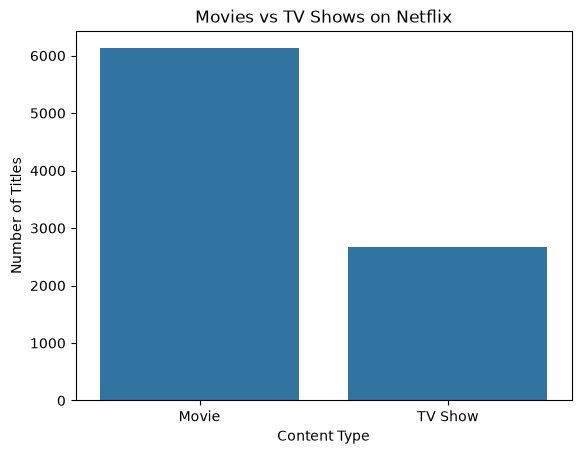

In [22]:
sns.countplot(x="type", data=df)
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

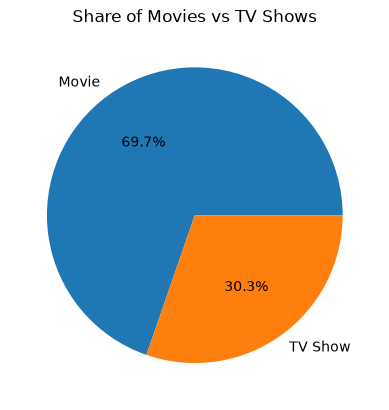

In [23]:
counts.plot.pie(autopct="%1.1f%%", ylabel="")
plt.title("Share of Movies vs TV Shows")
plt.show()

Cell 4: Compare proportions over time

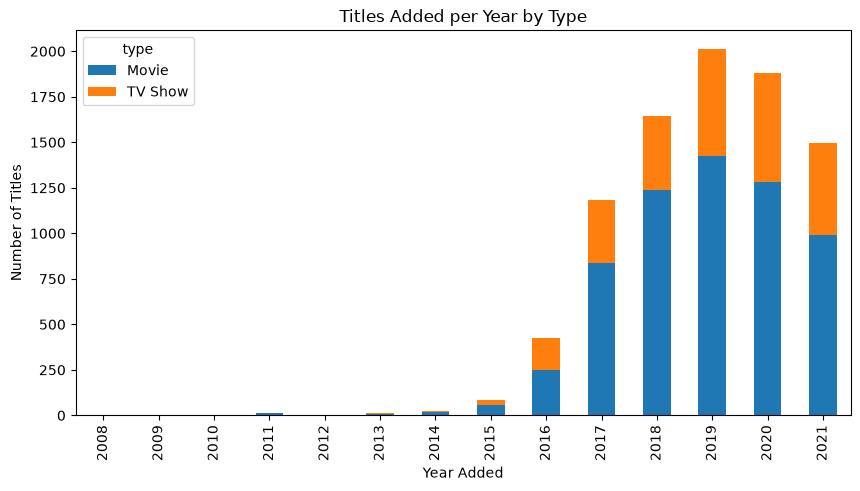

year_added
2016    41.1
2017    29.5
2018    25.0
2019    29.3
2020    31.7
2021    33.7
dtype: float64


In [24]:
type_by_year = pd.crosstab(df["year_added"], df["type"])
type_by_year.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Titles Added per Year by Type")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.show()

tv_share = (type_by_year["TV Show"] / type_by_year.sum(axis=1) * 100).round(1)
print(tv_share.loc[2016:2021])

Cell 5: Extra comparison with duration 

In [25]:
df.groupby("type")["duration_value"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Movie,6124.0,99.6,28.3,3.0,87.0,98.0,114.0,312.0
TV Show,2663.0,1.8,1.6,1.0,1.0,1.0,2.0,17.0


summarise the key findings:
1.Movies dominate the catalog.
2.out of 8787 titles,6124 are movies and 2663 are TV shows.
3.Additions peaked in 2019.
4.Titles added per year grew sharply from 2016 to 2019 anfd then declines in 2020 and 2021.
5.The 2021 figure is lower patrtly because the data runs to september 2021 only.
6.TV Shows are gaining shares.
7.Their shares of addition fell to a low of 25.0% in 2018 and has rises every year sice reaching 33.7% in 2021.
8.eventhough the formats are different the typical movies run about 98 minutes while the typical TV Shows has only 1 season.

conclusion: The catalog is movie heavy but TV shows have grown as a share of new content since 2018.